# ✂️ Notebook 02 — Patient-Level Data Splitting

**Phase 3 of the project**

**The most important rule:** Split PATIENTS, not images.

Why? One patient has ~96 images. If Patient P001's images appear in both
Train and Test, the model 'already knows' that patient → fake high accuracy.
This is called **Data Leakage**.

What this notebook does:
1. Loads metadata.csv
2. Gets the list of all unique patients
3. Splits patients into Train / Validation / Test (70 / 15 / 15)
4. Assigns every image to its patient's split
5. Saves the split info back to metadata.csv
6. Verifies no patient appears in more than one split

**Run each cell with Shift+Enter**

## 0. Setup & Imports

In [1]:
import sys
sys.path.insert(0, r'D:\Projects\ML')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from pathlib import Path

from src.config import METADATA_CSV, FIGURES_DIR, SPLITS_DIR, RANDOM_SEED
from src.utils import set_plot_style, save_figure, set_seed

set_plot_style()
set_seed(RANDOM_SEED)
print('Imports done!')
print(f'Metadata: {METADATA_CSV}')

🌱  Random seed set to 42
Imports done!
Metadata: D:\Projects\ML\metadata.csv


## 1. Load Metadata

In [2]:
metadata = pd.read_csv(METADATA_CSV)
print(f'Total images   : {len(metadata):,}')
print(f'Total patients : {metadata["patient_id"].nunique()}')
print(f'Classes        : {dict(metadata["class_name"].value_counts())}')
metadata.head(3)

Total images   : 7,909
Total patients : 82
Classes        : {'malignant': np.int64(5429), 'benign': np.int64(2480)}


,image_path,patient_id,class_name,label,subtype,magnification
0,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
1,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
2,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X


## 2. Get Patient-Level Info

Before splitting, we build a patient-level table.
Each row = one patient (not one image).

In [3]:
# Build patient-level table
# For each patient: what class are they? (A patient is either fully benign or fully malignant)
patient_df = (
    metadata
    .groupby('patient_id')
    .agg(
        class_name    = ('class_name', 'first'),
        label         = ('label', 'first'),
        subtype       = ('subtype', 'first'),
        n_images      = ('image_path', 'count'),
    )
    .reset_index()
)

print(f'Patient-level table:')
print(f'  Total patients : {len(patient_df)}')
print(f'  Benign patients: {len(patient_df[patient_df["class_name"]=="benign"])}')
print(f'  Malignant pats : {len(patient_df[patient_df["class_name"]=="malignant"])}')
patient_df.head()

Patient-level table:
  Total patients : 82
  Benign patients: 24
  Malignant pats : 58


,patient_id,class_name,label,subtype,n_images
0,SOB_B_A_14-22549AB,benign,0,adenosis,121
1,SOB_B_A_14-22549CD,benign,0,adenosis,132
2,SOB_B_A_14-22549G,benign,0,adenosis,130
3,SOB_B_A_14-29960CD,benign,0,adenosis,61
4,SOB_B_F_14-14134,benign,0,fibroadenoma,142


## 3. Stratified Patient Split

Split: **70% Train | 15% Validation | 15% Test**

We use `stratify=class_name` to ensure both splits have
roughly the same ratio of benign:malignant patients.

In [4]:
# Step 1: Split off 70% train, 30% temp
train_patients, temp_patients = train_test_split(
    patient_df,
    test_size   = 0.30,
    stratify    = patient_df['class_name'],
    random_state= RANDOM_SEED
)

# Step 2: Split the 30% temp into 15% val, 15% test
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size   = 0.50,
    stratify    = temp_patients['class_name'],
    random_state= RANDOM_SEED
)

print('Patient Split Results:')
print(f'  Train      : {len(train_patients)} patients')
print(f'  Validation : {len(val_patients)} patients')
print(f'  Test       : {len(test_patients)} patients')
print(f'  Total      : {len(train_patients)+len(val_patients)+len(test_patients)} patients')

Patient Split Results:
  Train      : 57 patients
  Validation : 12 patients
  Test       : 13 patients
  Total      : 82 patients


## 4. Verify No Patient Leakage

In [5]:
train_ids = set(train_patients['patient_id'])
val_ids   = set(val_patients['patient_id'])
test_ids  = set(test_patients['patient_id'])

train_val_overlap  = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap   = val_ids   & test_ids

print('Leakage Check:')
print(f'  Train & Val  overlap : {len(train_val_overlap)}  (must be 0)')
print(f'  Train & Test overlap : {len(train_test_overlap)} (must be 0)')
print(f'  Val & Test   overlap : {len(val_test_overlap)}  (must be 0)')

assert len(train_val_overlap) == 0,  'LEAKAGE DETECTED between Train and Val!'
assert len(train_test_overlap) == 0, 'LEAKAGE DETECTED between Train and Test!'
assert len(val_test_overlap) == 0,   'LEAKAGE DETECTED between Val and Test!'
print()
print('No leakage detected! Patient split is clean.')

Leakage Check:
  Train & Val  overlap : 0  (must be 0)
  Train & Test overlap : 0 (must be 0)
  Val & Test   overlap : 0  (must be 0)

No leakage detected! Patient split is clean.


## 5. Assign Split Labels to Every Image

In [6]:
# Create a mapping: patient_id -> split
split_map = {}
for pid in train_ids: split_map[pid] = 'train'
for pid in val_ids:   split_map[pid] = 'val'
for pid in test_ids:  split_map[pid] = 'test'

# Add 'split' column to metadata
metadata['split'] = metadata['patient_id'].map(split_map)

# Verify all images got a split
assert metadata['split'].isna().sum() == 0, 'Some images have no split assigned!'

print('Images per split:')
for split, grp in metadata.groupby('split'):
    n_b = len(grp[grp['class_name']=='benign'])
    n_m = len(grp[grp['class_name']=='malignant'])
    print(f'  {split:6s}: {len(grp):5,} images  (Benign={n_b}, Malignant={n_m})')

metadata.head(3)

Images per split:
  test  : 1,335 images  (Benign=625, Malignant=710)
  train : 5,403 images  (Benign=1597, Malignant=3806)
  val   : 1,171 images  (Benign=258, Malignant=913)


,image_path,patient_id,class_name,label,subtype,magnification,split
0,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X,train
1,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X,train
2,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X,train


## 6. Save Updated metadata.csv

In [7]:
metadata.to_csv(METADATA_CSV, index=False)

# Also save separate split lists for reference
train_patients.to_csv(SPLITS_DIR / 'train_patients.csv', index=False)
val_patients.to_csv(  SPLITS_DIR / 'val_patients.csv',   index=False)
test_patients.to_csv( SPLITS_DIR / 'test_patients.csv',  index=False)

print('Saved:')
print(f'  metadata.csv (with split column) -> {METADATA_CSV}')
print(f'  train_patients.csv -> {SPLITS_DIR}')
print(f'  val_patients.csv   -> {SPLITS_DIR}')
print(f'  test_patients.csv  -> {SPLITS_DIR}')

Saved:
  metadata.csv (with split column) -> D:\Projects\ML\metadata.csv
  train_patients.csv -> D:\Projects\ML\splits
  val_patients.csv   -> D:\Projects\ML\splits
  test_patients.csv  -> D:\Projects\ML\splits


## 7. Visualize the Split

📊  Saved figure → D:\Projects\ML\outputs\figures\02_data_split.png


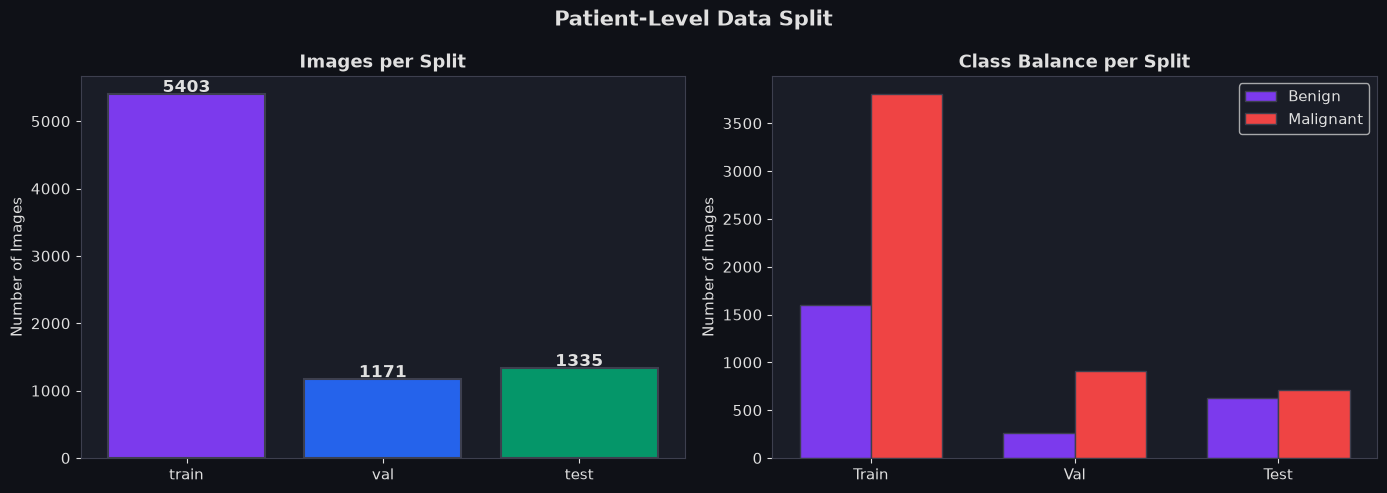

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Patient-Level Data Split', fontsize=15)
PALETTE = {'train': '#7c3aed', 'val': '#2563eb', 'test': '#059669'}

# --- Images per split ---
split_counts = metadata['split'].value_counts().reindex(['train','val','test'])
bars = axes[0].bar(split_counts.index, split_counts.values,
                   color=[PALETTE[s] for s in split_counts.index],
                   edgecolor='#3d3f4e', linewidth=1.5)
for bar, cnt in zip(bars, split_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, cnt + 30,
                 str(cnt), ha='center', fontsize=12, fontweight='bold')
axes[0].set_title('Images per Split')
axes[0].set_ylabel('Number of Images')

# --- Class balance within each split ---
split_class = metadata.groupby(['split','class_name']).size().unstack(fill_value=0)
split_class = split_class.reindex(['train','val','test'])
x = np.arange(len(split_class))
w = 0.35
axes[1].bar(x - w/2, split_class['benign'],    w, label='Benign',    color='#7c3aed', edgecolor='#3d3f4e')
axes[1].bar(x + w/2, split_class['malignant'], w, label='Malignant', color='#ef4444', edgecolor='#3d3f4e')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Train','Val','Test'])
axes[1].set_title('Class Balance per Split')
axes[1].set_ylabel('Number of Images')
axes[1].legend()

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '02_data_split.png')
plt.show()

## 8. Summary

In [9]:
print('='*55)
print('  PHASE 3 COMPLETE - Patient-Level Split')
print('='*55)
for split in ['train','val','test']:
    grp = metadata[metadata['split']==split]
    pats = grp['patient_id'].nunique()
    imgs = len(grp)
    print(f'  {split.upper():12s}: {pats:3d} patients | {imgs:5,} images')
print()
print('  No data leakage - patients kept separate!')
print('  metadata.csv updated with split column.')
print()
print('  Next: Notebook 03 - Image Preprocessing')
print('='*55)

  PHASE 3 COMPLETE - Patient-Level Split
  TRAIN       :  57 patients | 5,403 images
  VAL         :  12 patients | 1,171 images
  TEST        :  13 patients | 1,335 images

  No data leakage - patients kept separate!
  metadata.csv updated with split column.

  Next: Notebook 03 - Image Preprocessing
